In [ ]:
# [기본구현] 누적합 알고리즘
a_list = [1,3,3,5,3,2,7]
sum_list = [a_list[0]]
for i in range(1, len(a_list)) :
  sum_list.append(sum_list[i-1]+a_list[i])

print(sum_list)

[1, 4, 7, 12, 15, 17, 24]


In [ ]:
# [기본구현] 구간합 알고리즘
# L번 인덱스부터 R번 인덱스까지의 합을 구하고자 한다.
a_list = [1,3,3,5,3,2,7]
sum_list = [a_list[0]]
for i in range(1, len(a_list)) :
  sum_list.append(sum_list[i-1]+a_list[i])

L, R = map(int, input().split())
print(sum_list[R] - sum_list[L-1])

2 5
13


In [ ]:
# [실습과제1] 벼룩시장 일일 매출 집계

"""
[문제] "A번째 날부터 B번째 날까지 번 돈이 총 얼마인가?"라는 질문을 여러 번 하려고 합니다.
민수가 질문할 때마다 빠르게 해당 기간의 총매출을 계산해 주는 프로그램을 작성해 주세요.

[입력]
1. 부스를 운영한 일수를 저장하는 변수 N, 민수가 질문한 횟수 M (각각 100,000 이하)
2. 1일차부터 N일 차까지 매일 발생한 매출 N개가 주어짐.
3. 셋째 줄부터 M개의 줄에 걸쳐 구간 시작일 A와 종료일 B가 주어진다.
"""

n, m = map(int, input().split())

#누적 매출 리스트(prefix_price를 제작)
sold_price = list(map(int, input().split()))
prefix_price = [sold_price[0]]

for i in range(1, n) :
  prefix_price.append(prefix_price[i-1]+sold_price[i])

#여기서부터 쿼리 받기 시작.
for _ in range(0, m) :
  start, end = map(int, input().split())
  if start != 1 :
    print(prefix_price[end-1]-prefix_price[start-2])
  else :
    print(prefix_price[end-1])

5 3
10 20 30 40 50
1 3
60
2 4
90
3 3
30


In [ ]:
# [실습과제2] 과수원의 황금 사과 수확

"""
[문제]
  1. n*m 크기의 격자모양 과수원을 가꾸고 있다. 각 칸 (r,c)에는 자란 사과의 당도 점수가 적혀있다.
  2. 특정 정사각형 구역을 지정하여 그 구역 안에 있는 모든 사과의 당도 총합을 확인하고자 한다.
  3. 좌측 상단좌표 (x1,y1)과 우측하단 좌표 (x2,y2)를 질문할 때마다 해당 구역 내 사과 당도의 총합을 구해주는 프로그램을 작성하라.

[입력]
  1. 첫째줄에 과수원의 세로 크기 n과 가로 크기 m이 공백으로 구분되어 주어짐.
  2. 둘째줄부터 n개의 줄에 걸쳐 각 줄마다 m개의 사과 당도가 공백으로 구분되어 주어짐.
  3. 영희의 질문 횟수 q가 주어짐. (100,000개 이하)
  4. q개에 걸쳐 각 질문의 좌표가 공백으로 구분되어 주어짐.
"""

n, m = map(int, input().split())
the_map = []

for i in range(n) :
  the_val = [0] + list(map(int, input().split()))
  the_map.append(the_val)

prefix_val = [[0] for i in range(n)]

for i in range(0, n) :
  for j in range(1, m+1) :
    prefix_val[i].append(prefix_val[i][j-1]+the_map[i][j])

q = int(input())

for _ in range(q) :
  x1, y1, x2, y2 = map(int, input().split())
  answer = 0
  for i in range(x1-1, x2) : # <== 얘가 문제임.
    answer += prefix_val[i][y2] - prefix_val[i][y1-1]
  print(answer)

#[실행결과] TLE (Time Limit Error)

3 4
1 2 3 4
2 3 4 5
3 4 5 6
2
1 1 2 2
8
2 2 3 4
27


## 2차원 누적합에서 당황하지 않는 법.
1. 행별 1차원 누적합을 만들어서 **활용하지 않는다.**
2. 2차원 누적합 배열 생성의 점화식을 이용한다.
*   `S[i][j] = S[i-1][j] + S[i][j-1] - S[i-1][j-1] + A[i][j]`
*   `S[i-1][j] + S[i][j-1]` : 현재 위치에서 위쪽까지의 합과 왼쪽까지의 합
*   `S[i-1][j-1]` : 두 합에서 겹치는 부분
*   `A[i][j]` : 현재 더하려는 부분

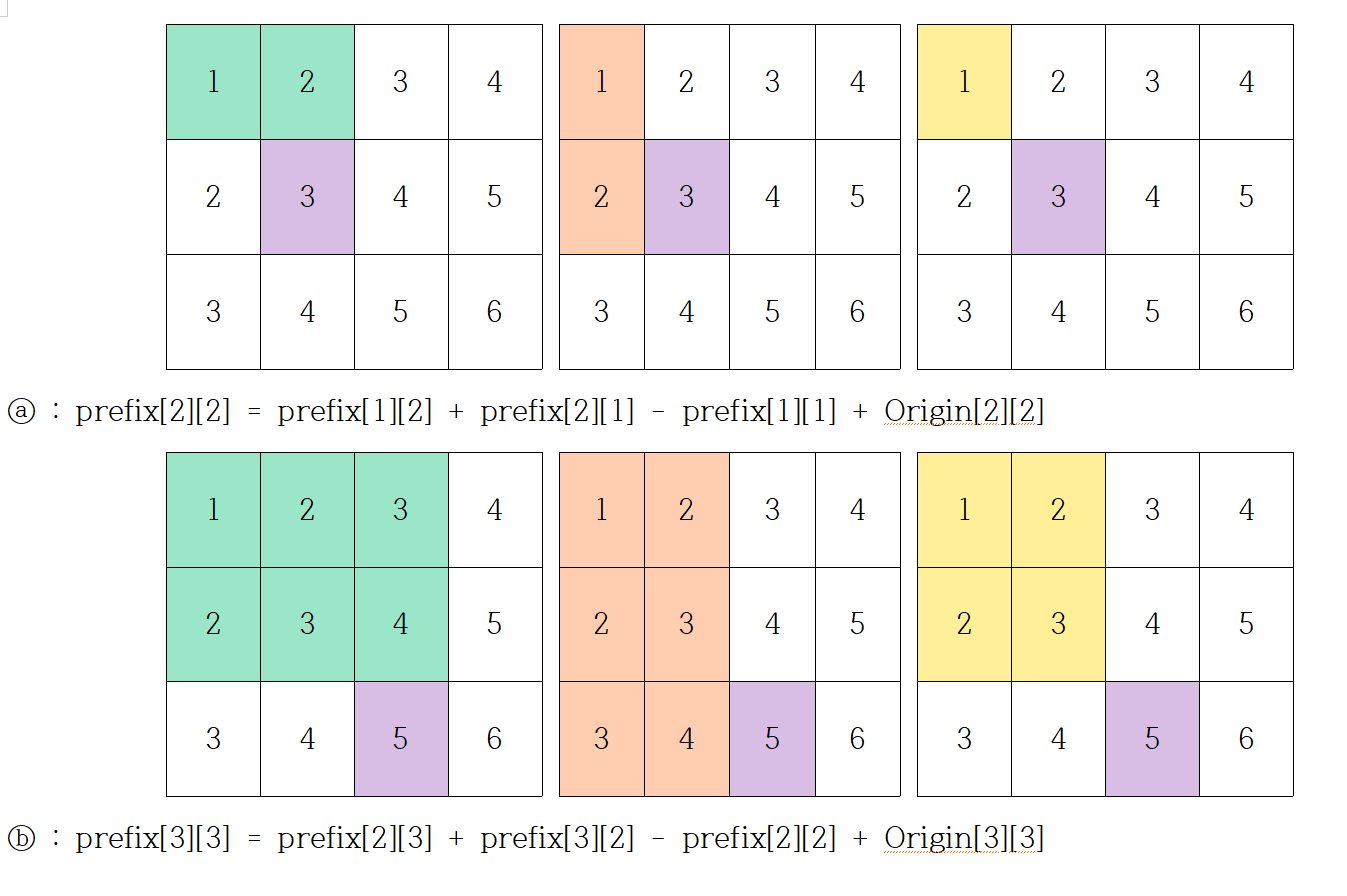


In [ ]:
# [실습과제2] 과수원의 황금 사과 수확

"""
[문제]
  1. n*m 크기의 격자모양 과수원을 가꾸고 있다. 각 칸 (r,c)에는 자란 사과의 당도 점수가 적혀있다.
  2. 특정 정사각형 구역을 지정하여 그 구역 안에 있는 모든 사과의 당도 총합을 확인하고자 한다.
  3. 좌측 상단좌표 (x1,y1)과 우측하단 좌표 (x2,y2)를 질문할 때마다 해당 구역 내 사과 당도의 총합을 구해주는 프로그램을 작성하라.

[입력]
  1. 첫째줄에 과수원의 세로 크기 n과 가로 크기 m이 공백으로 구분되어 주어짐.
  2. 둘째줄부터 n개의 줄에 걸쳐 각 줄마다 m개의 사과 당도가 공백으로 구분되어 주어짐.
  3. 영희의 질문 횟수 q가 주어짐. (100,000개 이하)
  4. q개에 걸쳐 각 질문의 좌표가 공백으로 구분되어 주어짐.
"""

n, m = map(int, input().split())
the_map = [[0] * (m+1)]

for _ in range(n) :
  the_val = [0] + list(map(int, input().split()))
  the_map.append(the_val)

prefix_val = [[0] * (m+1) for _ in range(n+1)]

for i in range(1, n+1) :
  for j in range(1, m+1) :
    prefix_val[i][j] = prefix_val[i-1][j] + prefix_val[i][j-1] - prefix_val[i-1][j-1] + the_map[i][j]

q = int(input())

for _ in range(q) :
  x1, y1, x2, y2 = map(int, input().split())
  print(prefix_val[x2][y2] - prefix_val[x1-1][y2] - prefix_val[x2][y1-1] + prefix_val[x1-1][y1-1])

# 차분 배열 (Difference Array, ABC419_#D IDEA)

## 1. 개념
배열의 특정 구간에 동일한 연산을 반복할 때, **구간의 시작점과 끝점만 기록하여 시간복잡도를 줄이는 기법**이다. 마지막에 누적합을 계산하여 각 위치의 최종 상태를 구한다.

## 2. 핵심 원리
구간 `[L, R]`에 `+1`을 적용하는 경우, 차분 배열 `diff`에 다음과 같이 기록한다.

```python
diff[L] += 1
diff[R + 1] -= 1
```

이후 누적합을 계산하면 해당 구간에만 `+1`이 적용된다.

## 3. 시간복잡도
- 구간 업데이트: `O(1)`
- 누적합 계산: `O(N)`
- 전체 시간복잡도: `O(N + M)` (`M`개의 구간 업데이트)

## 4. 주의사항
- 구간의 끝점 다음 위치에 변화를 기록하므로 배열 크기는 `N + 1` 이상으로 설정한다.
- 차분 배열은 구간 업데이트를 효율적으로 처리하는 기법이며, **덮어쓰기·토글·덧셈 등 실제 연산의 성질에 맞게 최종 결과를 계산해야 한다.**